# Policy Evaluation


Choose one method below and select **Restart Kernel and Run All**. The default runs only Blackjack baseline under a fixed policy. Run each TD method separately, then redraw the comparison from the saved CSVs. 


## 1. Imports
The TD files contain only their method's logic. Shared sampling, scoring, and plotting are in `evaluation_utils.py`.


In [1]:
from pathlib import Path
import sys
import json

project = next((p for p in [Path.cwd(), *Path.cwd().parents]
                if (p / 'policy_evaluation_enhancements' / 'baseline.py').exists()), None)
if project is None:
    raise FileNotFoundError('Open this notebook from the Project folder or its subfolders.')
sys.path.insert(0, str(project))

from policy_evaluation_enhancements.baseline import GridWorld
from policy_evaluation_enhancements import td_tabular, td_tabular_online
from policy_evaluation_enhancements import td_linear, td_linear_online, tomc
from policy_evaluation_enhancements.evaluation_utils import (
    METHODS, run, tune, save_rows, result_folder, plot_results)


## 2. Choose what to run

`METHOD`: `baseline`, `td_tabular_0`, `td_tabular`, `td_tabular_online`, `td_linear`, or `td_linear_online`. The `_online` files implement **True Online TD(λ)**; ordinary TD also learns from online samples.

`TASK = 'evaluation'` measures error under a fixed uniform policy. `TASK = 'policy_improvement'` draws the policy-gap curve using the same SPMD update. These are different experiments.

`METHOD = 'blackjack_comparison'` runs only Blackjack's TOMC, tabular TD(0), and tabular TD(λ), then draws one comparison plot. Set `ENVIRONMENT = 'blackjack'` for this option. `METHOD = 'all'` explicitly runs all six methods. To inspect the setup quickly, select one seed and fewer steps; TOMC may not finish coverage in a short run.


In [2]:
ENVIRONMENT = 'blackjack'
METHOD = 'blackjack_comparison'
TASK = 'evaluation'
TUNE = False

TUNING_SEEDS = [100, 101, 102]
TEST_SEEDS = [200, 201, 202, 203, 204]
SEEDS = TEST_SEEDS  # Use [200] for a single run.

if ENVIRONMENT not in ['gridworld', 'blackjack']:
    raise ValueError('Choose gridworld or blackjack.')
if METHOD not in METHODS + ['all', 'blackjack_comparison']:
    raise ValueError('Choose a listed method.')
if TASK not in ['evaluation', 'policy_improvement']:
    raise ValueError('Choose evaluation or policy_improvement.')
if not SEEDS or len(set(SEEDS)) != len(SEEDS) or set(SEEDS) & set(TUNING_SEEDS):
    raise ValueError('Use distinct test seeds, separate from tuning seeds.')

if ENVIRONMENT == 'gridworld':
    env = GridWorld()
    N_STEPS = 1_200_000 if TASK == 'evaluation' else 2_400_000
    TUNING_STEPS = 240_000
    UPDATE_EVERY = 10_000
else:
    from policy_evaluation_enhancements.baseline_blackjack import Blackjack
    env = Blackjack()
    N_STEPS = 40_000 if TASK == 'evaluation' else 120_000
    TUNING_STEPS = 12_000
    UPDATE_EVERY = 500

if METHOD == 'blackjack_comparison':
    if ENVIRONMENT != 'blackjack':
        raise ValueError('Select blackjack for blackjack_comparison.')
    selected_methods = ['baseline', 'td_tabular_0', 'td_tabular', 'td_tabular_online']
else:
    selected_methods = METHODS if METHOD == 'all' else [METHOD]
print(ENVIRONMENT, TASK, selected_methods, 'test seeds:', SEEDS)


blackjack evaluation ['baseline', 'td_tabular_0', 'td_tabular', 'td_tabular_online'] test seeds: [200, 201, 202, 203, 204]


## 3. Method settings

The nonzero-trace TD starting values come from the earlier three-seed tuning run. TD(0) starts with the same tabular learning rate; it has not been separately tuned. GridWorld's TOMC horizon and SPMD step were fallback defaults because tuning did not finish coverage on every seed. They are not claimed as successfully tuned.

Existing `parameters.json` values are reused. Set `TUNE = True` to select the evaluator's parameters by mean error across tuning seeds 100–102. This optional step adds runs. The common SPMD step stays at 0.5 for every method.


In [3]:
if ENVIRONMENT == 'gridworld':
    alpha_lambda = {'baseline': (0.0, 0.0), 'td_tabular_0': (0.1, 0.0), 'td_tabular': (0.1, 0.9),
                    'td_tabular_online': (0.1, 0.9), 'td_linear': (0.05, 0.9),
                    'td_linear_online': (0.1, 0.6)}
    HORIZON = 100
else:
    alpha_lambda = {'baseline': (0.0, 0.0), 'td_tabular_0': (0.05, 0.0), 'td_tabular': (0.05, 0.3),
                    'td_tabular_online': (0.05, 0.3), 'td_linear': (0.01, 0.9),
                    'td_linear_online': (0.01, 0.9)}
    HORIZON = 4

SPMD_STEP = 0.5


## 4. Run the selected method


In [4]:
for method in selected_methods:
    folder = result_folder(method, ENVIRONMENT)
    folder.mkdir(parents=True, exist_ok=True)
    parameter_file = folder / 'parameters.json'
    alpha, lam = alpha_lambda[method]
    params = dict(alpha=alpha, lam=lam, horizon=HORIZON, step_size=SPMD_STEP)
    source = 'provided starting values'
    if parameter_file.exists():
        saved = json.loads(parameter_file.read_text())
        params = saved['parameters']
        source = saved['source']
    if method == 'td_tabular_0':
        params['lam'] = 0.0
    # Keep the policy optimizer common to all evaluators.
    params['step_size'] = SPMD_STEP
    if TUNE:
        params, tuning_rows, tuning_means, source = tune(
            env, method, TUNING_STEPS, TUNING_SEEDS, params, UPDATE_EVERY)
        save_rows(folder / 'tuning.csv', tuning_rows)
        save_rows(folder / 'tuning_means.csv', tuning_means)
    parameter_file.write_text(json.dumps(dict(parameters=params, source=source), indent=2) + '\n')
    configuration = dict(environment=ENVIRONMENT, method=method, task=TASK,
                         test_seeds=SEEDS, tuning_seeds=TUNING_SEEDS,
                         parameters=params, parameter_source=source,
                         n_steps=N_STEPS, update_every=UPDATE_EVERY)
    (folder / (TASK + '_settings.json')).write_text(json.dumps(configuration, indent=2) + '\n')
    rows = []
    for seed in SEEDS:
        history = run(env, method, TASK, N_STEPS, seed, **params,
                      update_every=UPDATE_EVERY)
        rows.extend(dict(environment=ENVIRONMENT, method=method, **row) for row in history)
        save_rows(folder / (TASK + '.csv'), rows)
        last = history[-1]
        print('Finished:', method, seed, last['status'], 'missing pairs:', last['pending_pairs'])
    print('Saved:', folder)


baseline, seed 200: 4000/40000 steps; missing pairs=4
baseline, seed 200: 8000/40000 steps; missing pairs=10
baseline, seed 200: 12000/40000 steps; missing pairs=36
baseline, seed 200: 16000/40000 steps; missing pairs=3
baseline, seed 200: 20000/40000 steps; missing pairs=10
baseline, seed 200: 24000/40000 steps; missing pairs=1
baseline, seed 200: 28000/40000 steps; missing pairs=1
baseline, seed 200: 32000/40000 steps; missing pairs=9
baseline, seed 200: 36000/40000 steps; missing pairs=1
baseline, seed 200: 40000/40000 steps; missing pairs=1
Finished: baseline 200 ready missing pairs: 1
baseline, seed 201: 4000/40000 steps; missing pairs=10
baseline, seed 201: 8000/40000 steps; missing pairs=29
baseline, seed 201: 12000/40000 steps; missing pairs=7
baseline, seed 201: 16000/40000 steps; missing pairs=16
baseline, seed 201: 20000/40000 steps; missing pairs=7
baseline, seed 201: 24000/40000 steps; missing pairs=4
baseline, seed 201: 28000/40000 steps; missing pairs=19
baseline, seed 2

## 5. Compare saved results


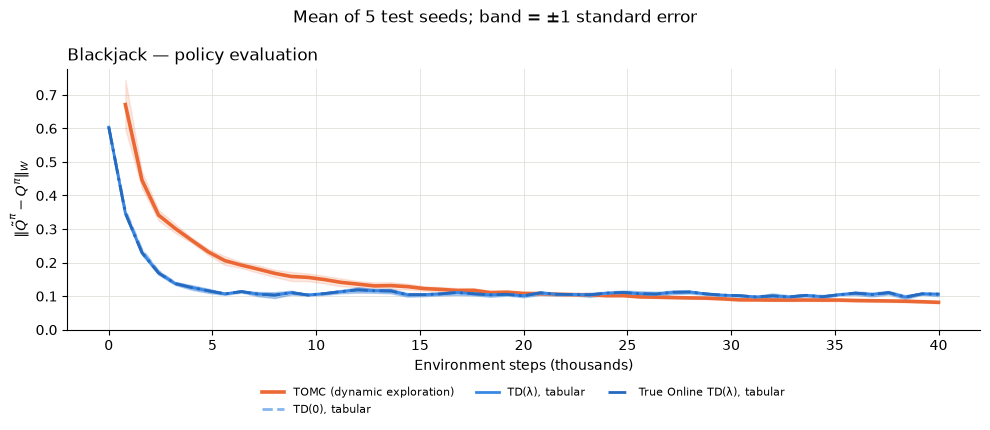

In [5]:
plot_methods = selected_methods if METHOD == 'blackjack_comparison' else None
plot_results(ENVIRONMENT, TASK, SEEDS, methods=plot_methods)
